# Demo 10 - Descida do Gradiente: como um modelo aprende

### MBA em AI Engineering & Multi Agents - Machine Learning Foundations & Classic Models.

### Prof. Dr. Ahirton Lopes (profahirton.lopes@fiap.com.br)

## Objetivo da demo

Até aqui, na disciplina, treinamos modelos chamando `.fit()` e confiando no resultado. Nesta demo vamos abrir essa caixa e responder à pergunta que sustenta **todas** as redes neurais:

> **Como um modelo encontra, sozinho, os valores de seus parâmetros?**

A resposta é a **Descida do Gradiente**. Vamos ver:

| Seção | Conteúdo |
| --- | --- |
| 1 | A intuição: descer a montanha no escuro |
| 2 | Descida do gradiente em $f(x) = x^2$ e o efeito da taxa de aprendizado |
| 3 | Um velho conhecido: a regressão linear da Aula 1, agora aprendida passo a passo |
| 4 | Funções de ativação e por que a não-linearidade é obrigatória |
| 5 | Conclusão e ponte para a Demo 11 |

## 1. A intuição: descer a montanha no escuro

Imagine que você está no alto de uma montanha, à noite, sem lanterna, e quer chegar ao vale. Você não enxerga a paisagem inteira, mas sente com os pés **para onde o chão desce mais**. Então dá um passo nessa direção, sente de novo, dá outro passo, e assim por diante.

Em Machine Learning:

- a **montanha** é a **função de perda** (o quanto o modelo está errando);
- a **posição** em que você está são os **parâmetros** do modelo (pesos e viés);
- a **inclinação** sentida com os pés é o **gradiente** (a derivada da perda em relação a cada parâmetro);
- o **tamanho do passo** é a **taxa de aprendizado** (*learning rate*).

A regra de atualização é sempre a mesma:

$$\theta_{novo} = \theta_{atual} - \eta \cdot \nabla L(\theta_{atual})$$

onde $\theta$ são os parâmetros, $\eta$ é a taxa de aprendizado e $\nabla L$ é o gradiente da perda. O sinal de **menos** é o "descer": o gradiente aponta para onde a perda **sobe**, então andamos no sentido oposto.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## 2. Descida do gradiente em $f(x) = x^2$

Começamos com a função mais simples possível: $f(x) = x^2$. Sabemos que o mínimo está em $x = 0$, então fica fácil conferir se o algoritmo chega lá.

A derivada é $f'(x) = 2x$. Ela nos diz a inclinação em qualquer ponto:

- em $x = 5$, a derivada é $10$ (subida forte para a direita), então andamos para a esquerda;
- em $x = -3$, a derivada é $-6$ (subida para a esquerda), então andamos para a direita.

In [2]:
def f(x):
    return x ** 2

def df(x):
    return 2 * x

def descida_do_gradiente(x_inicial, taxa_aprendizado, n_passos):
    """Executa a descida do gradiente e devolve o histórico de posições."""
    x = x_inicial
    historico = [x]
    for _ in range(n_passos):
        gradiente = df(x)
        x = x - taxa_aprendizado * gradiente   # o passo para baixo
        historico.append(x)
    return np.array(historico)

hist = descida_do_gradiente(x_inicial=5.0, taxa_aprendizado=0.1, n_passos=30)

for passo in [0, 1, 2, 5, 10, 20, 30]:
    print(f'Passo {passo:2d}: x = {hist[passo]:8.4f}   f(x) = {f(hist[passo]):8.4f}')

Passo  0: x =   5.0000   f(x) =  25.0000
Passo  1: x =   4.0000   f(x) =  16.0000
Passo  2: x =   3.2000   f(x) =  10.2400
Passo  5: x =   1.6384   f(x) =   2.6844
Passo 10: x =   0.5369   f(x) =   0.2882
Passo 20: x =   0.0576   f(x) =   0.0033
Passo 30: x =   0.0062   f(x) =   0.0000


### O hiperparâmetro mais importante: a taxa de aprendizado

A taxa de aprendizado decide o tamanho do passo. Vamos comparar três escolhas, partindo do mesmo ponto ($x = 5$) e dando o mesmo número de passos (30):

- **0.01**: passos minúsculos;
- **0.1**: passos razoáveis;
- **1.05**: passos grandes demais.

Taxa  0.01: x final =       2.7274
Taxa   0.1: x final =       0.0062
Taxa  1.05: x final =      87.2470


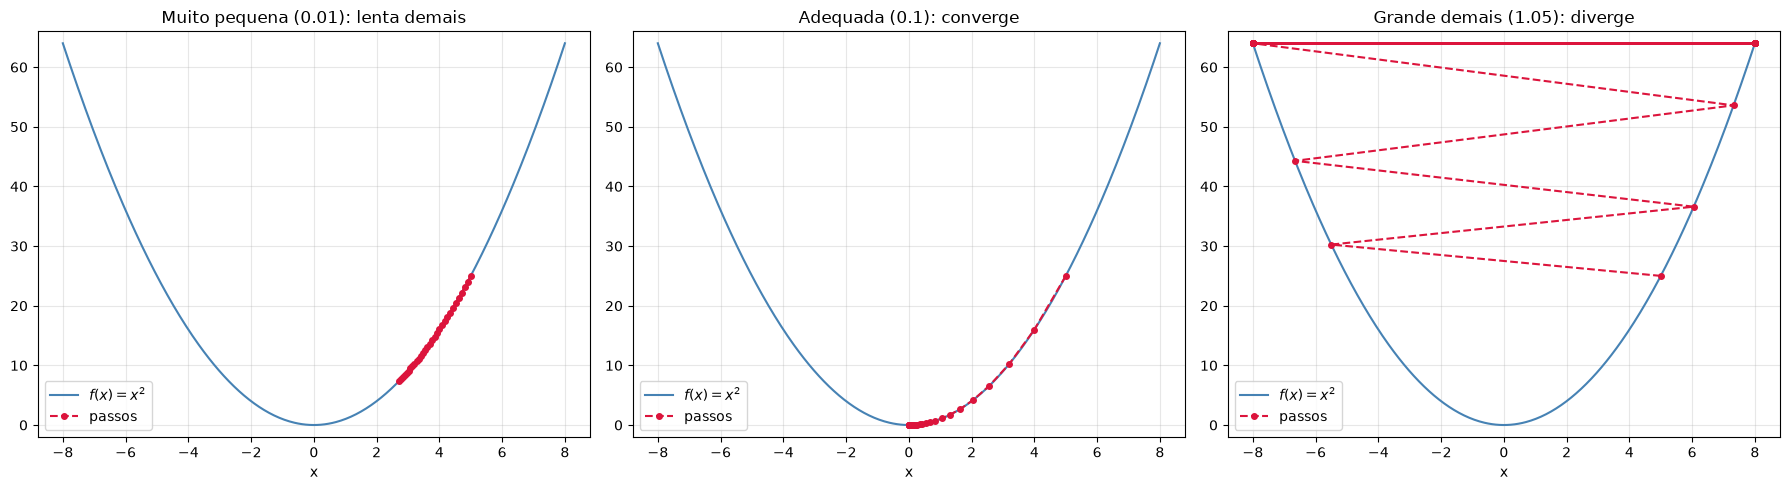

In [3]:
taxas = [0.01, 0.1, 1.05]
titulos = ['Muito pequena (0.01): lenta demais',
           'Adequada (0.1): converge',
           'Grande demais (1.05): diverge']

x_curva = np.linspace(-8, 8, 400)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, taxa, titulo in zip(axes, taxas, titulos):
    h = descida_do_gradiente(5.0, taxa, 30)
    h_plot = np.clip(h, -8, 8)  # só para caber no gráfico
    ax.plot(x_curva, f(x_curva), color='steelblue', label='$f(x) = x^2$')
    ax.plot(h_plot, f(h_plot), 'o--', color='crimson', markersize=4, label='passos')
    ax.set_title(titulo)
    ax.set_xlabel('x')
    ax.set_ylim(-2, 66)
    ax.grid(alpha=0.3)
    ax.legend()
    print(f'Taxa {taxa:>5}: x final = {h[-1]:12.4f}')

plt.tight_layout()
plt.show()

**O que observar:**

- com **0.01**, depois de 30 passos ainda estamos longe do mínimo. O modelo aprenderia, mas levaria muito tempo (muitas épocas, muito custo de computação);
- com **0.1**, chegamos praticamente a zero;
- com **1.05**, cada passo **passa do ponto** e cai mais alto do outro lado. O valor explode. Em uma rede neural de verdade, é isso que aparece como uma perda que vira `nan` no meio do treino.

Guarde essa imagem: quando vocês treinarem redes na próxima disciplina e a perda não cair (ou explodir), a primeira suspeita é sempre a taxa de aprendizado.

## 3. Um velho conhecido: a regressão linear, aprendida passo a passo

Na Aula 1 usamos regressão linear com o `scikit-learn`, que resolve o problema com uma fórmula fechada (mínimos quadrados). Agora vamos treinar **o mesmo modelo** do jeito que uma rede neural treina: começando de parâmetros aleatórios e descendo o gradiente da perda.

O modelo é $\hat{y} = w \cdot x + b$ e a perda é o **MSE** (erro quadrático médio), que vocês já conhecem da Demo 3:

$$L(w, b) = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2$$

As derivadas (o gradiente) são:

$$\frac{\partial L}{\partial w} = \frac{2}{n} \sum (\hat{y}_i - y_i)\, x_i \qquad \frac{\partial L}{\partial b} = \frac{2}{n} \sum (\hat{y}_i - y_i)$$

Vamos usar um cenário de negócio simples: **gasto com anúncios (em milhares de reais) x vendas (em milhares de reais)**, com dados sintéticos gerados a partir de uma relação verdadeira conhecida ($vendas = 3 \cdot anuncios + 20$, mais ruído).

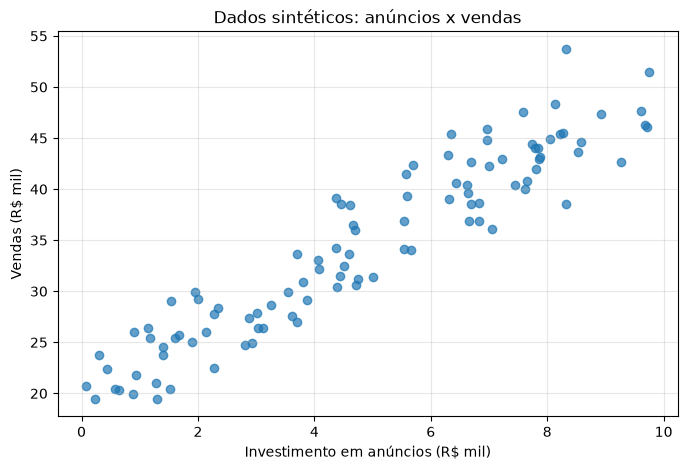

In [4]:
rng = np.random.default_rng(42)
anuncios = rng.uniform(0, 10, 100)                       # investimento em anúncios (R$ mil)
vendas = 3 * anuncios + 20 + rng.normal(0, 3, 100)       # vendas (R$ mil), com ruído

plt.figure(figsize=(8, 5))
plt.scatter(anuncios, vendas, alpha=0.7)
plt.xlabel('Investimento em anúncios (R$ mil)')
plt.ylabel('Vendas (R$ mil)')
plt.title('Dados sintéticos: anúncios x vendas')
plt.grid(alpha=0.3)
plt.show()

In [5]:
w, b = 0.0, 0.0          # começamos "sem saber nada"
taxa_aprendizado = 0.01
epocas = 2000
historico_perda = []
n = len(anuncios)

inicio = time.time()
for epoca in range(epocas):
    previsao = w * anuncios + b                      # 1. forward: o modelo faz uma previsão
    erro = previsao - vendas
    perda = np.mean(erro ** 2)                       # 2. mede o quanto errou (MSE)
    historico_perda.append(perda)

    grad_w = (2 / n) * np.sum(erro * anuncios)       # 3. calcula a inclinação (gradiente)
    grad_b = (2 / n) * np.sum(erro)

    w -= taxa_aprendizado * grad_w                   # 4. dá um passo para baixo
    b -= taxa_aprendizado * grad_b

    if epoca in [0, 10, 100, 500, 1999]:
        print(f'Época {epoca:4d}: perda (MSE) = {perda:9.3f}   w = {w:6.3f}   b = {b:6.3f}')

print(f'\nTempo de treino: {time.time() - inicio:.3f} s')

Época    0: perda (MSE) =  1270.725   w =  3.812   b =  0.691
Época   10: perda (MSE) =    86.190   w =  5.854   b =  1.891
Época  100: perda (MSE) =    42.139   w =  4.884   b =  8.044
Época  500: perda (MSE) =     9.434   w =  3.311   b = 18.018
Época 1999: perda (MSE) =     8.630   w =  3.023   b = 19.844

Tempo de treino: 0.007 s


Agora vamos comparar com a solução exata do `scikit-learn` (a mesma `LinearRegression` da Aula 1).

Descida do gradiente : w = 3.023   b = 19.844
scikit-learn (exato) : w = 3.023   b = 19.846
Relação verdadeira   : w = 3.000   b = 20.000


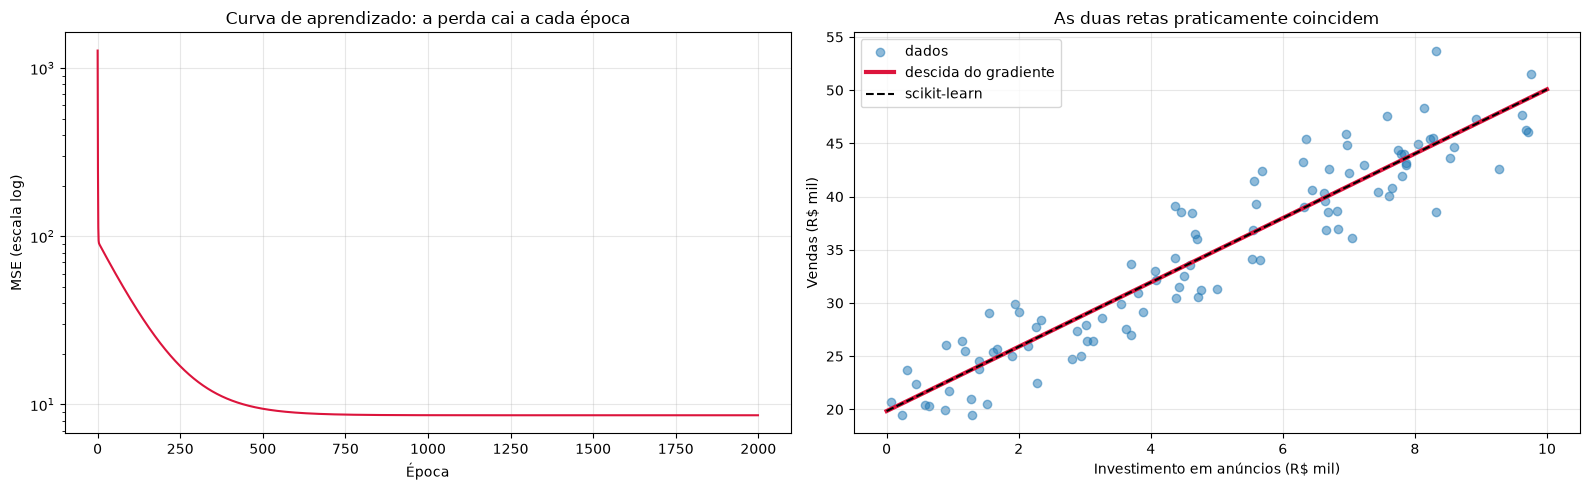

In [6]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression().fit(anuncios.reshape(-1, 1), vendas)

print(f'Descida do gradiente : w = {w:.3f}   b = {b:.3f}')
print(f'scikit-learn (exato) : w = {lr.coef_[0]:.3f}   b = {lr.intercept_:.3f}')
print('Relação verdadeira   : w = 3.000   b = 20.000')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(historico_perda, color='crimson')
axes[0].set_yscale('log')
axes[0].set_title('Curva de aprendizado: a perda cai a cada época')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE (escala log)')
axes[0].grid(alpha=0.3)

x_linha = np.linspace(0, 10, 100)
axes[1].scatter(anuncios, vendas, alpha=0.5, label='dados')
axes[1].plot(x_linha, w * x_linha + b, color='crimson', linewidth=3, label='descida do gradiente')
axes[1].plot(x_linha, lr.coef_[0] * x_linha + lr.intercept_, 'k--', label='scikit-learn')
axes[1].set_title('As duas retas praticamente coincidem')
axes[1].set_xlabel('Investimento em anúncios (R$ mil)')
axes[1].set_ylabel('Vendas (R$ mil)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**A mensagem desta seção:** os quatro passos do laço acima (prever, medir o erro, calcular o gradiente, atualizar) são **exatamente** o ciclo de treino de uma rede neural. A diferença é de escala:

| | Regressão linear desta demo | Rede neural moderna |
| --- | --- | --- |
| Parâmetros | 2 ($w$ e $b$) | de milhares a bilhões |
| Gradiente | 2 derivadas escritas à mão | calculado automaticamente pelo **backpropagation** |
| Formato da perda | uma "tigela" com um único mínimo | uma paisagem cheia de vales e platôs |

E por que não usar a fórmula fechada sempre, como o `scikit-learn` faz? Porque ela só existe para modelos muito simples. Para uma rede com milhões de parâmetros e funções não-lineares, não há fórmula: **descer o gradiente é o único caminho viável**.

## 4. Funções de ativação: por que a não-linearidade é obrigatória

Um neurônio artificial faz duas coisas: (1) calcula uma soma ponderada das entradas e (2) passa o resultado por uma **função de ativação**. Vamos ver as três mais comuns e as suas derivadas, que são o que a descida do gradiente usa.

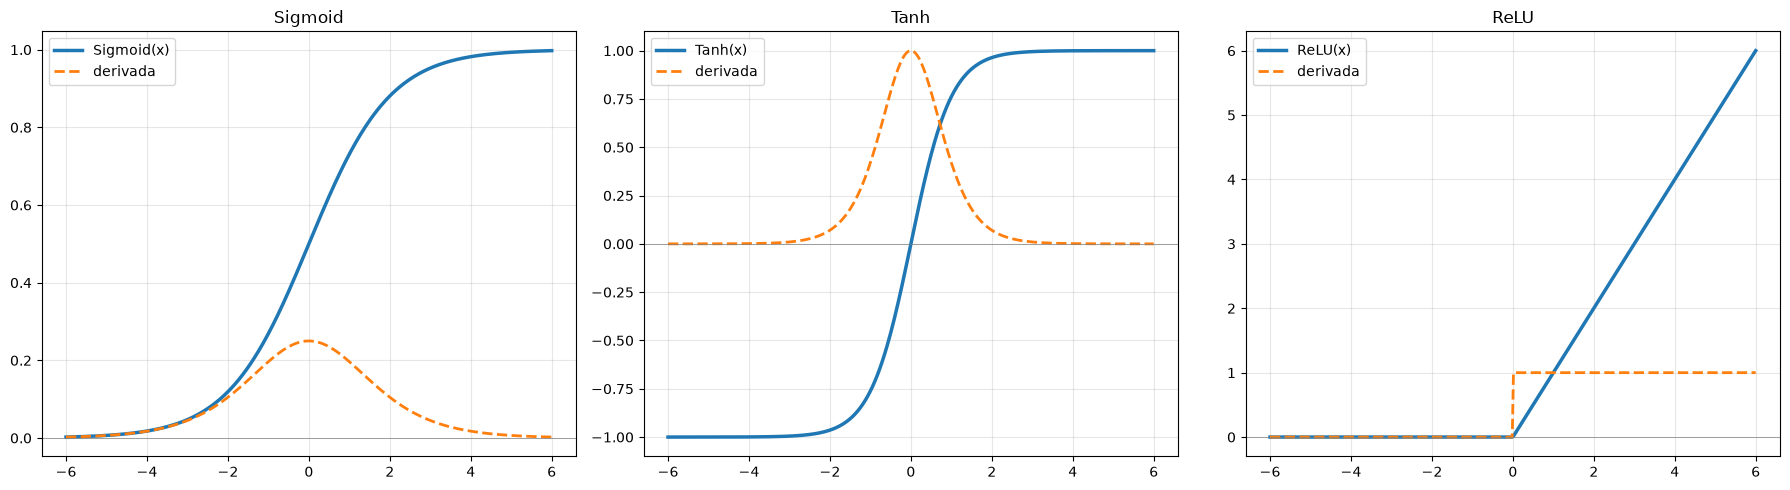

Derivada máxima da sigmoid: 0.25
Derivada da sigmoid em x = 6: 0.0025


In [7]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def relu(x):
    return np.maximum(0, x)

x_vals = np.linspace(-6, 6, 400)
funcoes = {
    'Sigmoid': (sigmoid(x_vals), sigmoid(x_vals) * (1 - sigmoid(x_vals))),
    'Tanh': (np.tanh(x_vals), 1 - np.tanh(x_vals) ** 2),
    'ReLU': (relu(x_vals), (x_vals > 0).astype(float)),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nome, (y, dy)) in zip(axes, funcoes.items()):
    ax.plot(x_vals, y, linewidth=2.5, label=f'{nome}(x)')
    ax.plot(x_vals, dy, '--', linewidth=2, label='derivada')
    ax.set_title(nome)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

print(f'Derivada máxima da sigmoid: {np.max(funcoes["Sigmoid"][1]):.2f}')
print(f'Derivada da sigmoid em x = 6: {funcoes["Sigmoid"][1][-1]:.4f}')

**O que observar nas derivadas (linhas tracejadas):**

- a derivada da **sigmoid** é no máximo **0.25** e quase **zero** nas pontas. Em uma rede com muitas camadas, o backpropagation multiplica essas derivadas camada após camada, e o sinal de aprendizado vai sumindo. Esse é o famoso **problema do gradiente que desaparece** (*vanishing gradient*), que vocês vão aprofundar na próxima disciplina;
- a **ReLU** tem derivada **1** para entradas positivas: o sinal passa inteiro. Esse detalhe simples é um dos motivos pelos quais redes profundas passaram a treinar bem a partir de 2010-2012.

### E se não usássemos ativação nenhuma?

Vamos empilhar duas "camadas" puramente lineares (multiplicações de matriz) e ver o que acontece.

In [8]:
rng = np.random.default_rng(0)
W1 = rng.normal(size=(3, 4))   # camada 1: 4 entradas -> 3 neurônios
W2 = rng.normal(size=(2, 3))   # camada 2: 3 neurônios -> 2 saídas
x = rng.normal(size=(4,))

duas_camadas = W2 @ (W1 @ x)          # passa pela camada 1 e depois pela camada 2
uma_camada = (W2 @ W1) @ x            # uma única matriz equivalente

print('Saída com duas camadas lineares:', np.round(duas_camadas, 4))
print('Saída com UMA camada equivalente:', np.round(uma_camada, 4))
print('São iguais?', np.allclose(duas_camadas, uma_camada))

# Agora com uma ReLU entre as camadas
com_relu = W2 @ relu(W1 @ x)
print('\nCom ReLU entre as camadas:', np.round(com_relu, 4))
print('Ainda é igual à camada única?', np.allclose(com_relu, uma_camada))

Saída com duas camadas lineares: [ 1.6116 -0.2143]
Saída com UMA camada equivalente: [ 1.6116 -0.2143]
São iguais? True

Com ReLU entre as camadas: [-0.2807 -0.6983]
Ainda é igual à camada única? False


Sem função de ativação, **empilhar camadas não serve para nada**: duas (ou cem) camadas lineares colapsam em uma única transformação linear, que só consegue desenhar fronteiras retas. Basta uma não-linearidade entre elas (a ReLU, no exemplo) para a rede ganhar poder de representação de verdade.

É exatamente isso que vamos ver acontecer na prática na próxima demo, com um problema que nenhuma reta resolve.

## 5. Conclusão

- **Treinar um modelo é descer uma montanha**: prever, medir o erro, calcular o gradiente e atualizar os parâmetros, repetindo até a perda parar de cair.
- A **taxa de aprendizado** controla o tamanho do passo: pequena demais desperdiça tempo, grande demais faz o treino divergir.
- A regressão linear da Aula 1 pode ser aprendida **pelo mesmo laço** que treina uma rede neural; a rede só tem muito mais parâmetros e usa o **backpropagation** para calcular os gradientes automaticamente.
- **Funções de ativação** dão não-linearidade à rede. Sem elas, qualquer número de camadas equivale a uma só. A ReLU virou padrão em camadas ocultas por deixar o gradiente fluir.

**Próximo passo (Demo 11):** juntar neurônios, ativações e descida do gradiente para resolver o problema que derrubou o perceptron em 1969, o XOR.